# Point- and line-source benchmarks

Select one Taiwan event, then run the notebook from top to bottom:
1. Event settings.
2. Point-source Chao20 prediction.
3. Line-source geometry and Chao20 prediction.
4. KF prediction at the evaluation time.
5. Comparison of point source, line source and KF.

PGA is in gal (cm/s²), distances in km and Vs30 in m/s. Alert outcomes use a
25-gal threshold and are given as percentages of all stations.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Geod

ROOT = Path.cwd().resolve()
if not (ROOT / "earthquake_index.csv").is_file():
    ROOT = ROOT.parent
if not (ROOT / "earthquake_index.csv").is_file():
    raise FileNotFoundError("Run from publication_release or its notebook directory.")
sys.path.insert(0, str(ROOT / "GMPE code"))
sys.path.insert(0, str(ROOT))
from GMPE_Chao19 import Chao19H
from vdist import vdist

## 1. Event settings

| ID | Event | AutoBATS Mw | Rupture direction |
| --- | --- | --- | --- |
| 1 | Hualien | 7.3 | 21° |
| 2 | Meinong | 6.4 | 299° |
| 3 | Chihshang | 7.0 | 26° |

Both benchmarks use the AutoBATS Mw and the final CWA hypocenter from
`earthquake_index.csv`. The KF settings are those of `Run_KalmanFilter.ipynb`.

In [2]:
EVENT_ID = 1
INIT_SEC = 5  # time index whose station list is used
BENCHMARKS = {
    1: dict(name="Hualien", magnitude=7.3, strike=21),
    2: dict(name="Meinong", magnitude=6.4, strike=299),
    3: dict(name="Chihshang", magnitude=7.0, strike=26),
}

# Taiwan KF settings of Run_KalmanFilter.ipynb
EVALUATION_SECOND = {1: 35, 2: 25, 3: 25}
HISTORY_END_SECOND = 40
OBS_VARIANCE = 1e-4
Q = np.diag([1e-8, 1e-7, 5e-5, 1e-5, 5e-5, 5e-5])
VS_TRUE = 3.0  # vertical S-wave speed, km/s
V_APP = 2.6    # horizontal PGA-front speed, km/s
MIN_STATIONS = 5
KF_SETTINGS = {
    1: dict(magnitude=6.2, start=5),
    2: dict(magnitude=6.1, start=13),
    3: dict(magnitude=6.2, start=10),
}

events = pd.read_csv(ROOT / "earthquake_index.csv", index_col="num")


def load_event(event_id):
    event = events.loc[event_id]
    event_key = event["time"].replace("T", "")
    data = pd.read_csv(
        ROOT / "RuptureParaTime_new" / f"{event_key}_RuptureParaTimeByStation_new.csv",
        index_col=0,
    )
    depth = float(event["hypodepth"])
    distance_m, azimuth, _ = vdist(
        np.full(len(data), float(event["hypolat"])),
        np.full(len(data), float(event["hypolon"])),
        data["Latitude"].to_numpy(), data["Longitude"].to_numpy(),
    )
    data["SRepi"] = distance_m / 1000
    data["SRhypo"] = np.sqrt(data["SRepi"] ** 2 + depth ** 2)
    data["Azimuth"] = azimuth
    return event, data, depth


def chao20_gal(magnitude, rrup, ztor, vs30):
    """Chao20 PGA in gal with crustal strike-slip flags (FSS=1)."""
    pga_g, *_ = Chao19H(0, magnitude, rrup, ztor, vs30, -999,
                        0, 1, 0, 0, 0, 0, 0, 0)
    return pga_g.flatten() * 980 * 1.22


bench = BENCHMARKS[EVENT_ID]
event, data, depth = load_event(EVENT_ID)
stations = data.loc[[INIT_SEC]].copy()
final_pga = stations["EndRealPGA"].to_numpy()
valid = final_pga > 0
print(f"Event {EVENT_ID}: {bench['name']}, {event['time']}, Mw {bench['magnitude']}, "
      f"depth {depth} km, {len(stations)} stations")

Event 1: Hualien, 20240402T2358, Mw 7.3, depth 22.52 km, 439 stations


## 2. Point-source prediction

Chao20 is evaluated at the AutoBATS Mw with crustal strike-slip flags,
hypocentral distance as Rrup and hypocentral depth as Ztor, and converted from
g to gal with `980 × 1.22`.

In [3]:
def point_source(bench, stations, depth):
    return chao20_gal(bench["magnitude"], stations["SRhypo"].to_numpy(), depth,
                      stations["Vs30"].to_numpy())

point_pga = point_source(bench, stations, depth)

## 3. Line-source prediction

The line source is a horizontal trace starting at the epicenter along the
adopted rupture direction, at a constant depth equal to the final hypocentral
depth, with no fault dip. Its length follows Wells & Coppersmith (1994),
`round(10**((Mw − 5.08) / 1.16))` km, sampled every 1 km. Rrup is the shortest
3-D distance to the trace, and the hypocentral depth is used as Ztor.

In [4]:
geod = Geod(ellps="WGS84")


def line_source(bench, event, stations, depth):
    magnitude = bench["magnitude"]
    fault_length = round(10 ** ((magnitude - 5.08) / 1.16))
    along_m = np.arange(0.0, fault_length + 1e-9, 1.0) * 1000.0
    trace_lon, trace_lat, _ = geod.fwd(
        np.full_like(along_m, float(event["hypolon"])),
        np.full_like(along_m, float(event["hypolat"])),
        np.full_like(along_m, bench["strike"]), along_m,
    )
    lat = stations["Latitude"].to_numpy()
    lon = stations["Longitude"].to_numpy()
    repi_line = np.min(np.column_stack([
        vdist(np.full_like(lat, trace_lat[i]), np.full_like(lon, trace_lon[i]), lat, lon)[0] / 1000.0
        for i in range(len(trace_lat))
    ]), axis=1)
    rrup_line = np.sqrt(repi_line**2 + depth**2)
    pga = chao20_gal(magnitude, rrup_line, depth, stations["Vs30"].to_numpy())
    return pga, fault_length

line_pga, fault_length = line_source(bench, event, stations, depth)
print(f"Line source: length {fault_length} km, direction {bench['strike']}°, depth (Ztor) {depth} km")

Line source: length 82 km, direction 21°, depth (Ztor) 22.52 km


## 4. KF prediction

The Taiwan KF of `Run_KalmanFilter.ipynb`: least-square fit of the initial
Chao20 prediction, updates with stations inside `V_APP × (t − depth / VS_TRUE)`,
zero PGA replaced by `1e-10` and the covariance update `(I − KH)P`. The
prediction at the evaluation time is used.

In [5]:
def design_matrix(frame, directional=True):
    ln_r = np.log(frame["SRhypo"].to_numpy())
    terms = [ln_r**2, ln_r, np.log(frame["Vs30"].to_numpy() / 760), np.ones(len(frame))]
    if directional:
        theta = np.deg2rad(frame["Azimuth"].to_numpy())
        terms.extend([np.cos(theta), np.sin(theta)])
    return np.column_stack(terms)


def kf_prediction(event_id, data, stations, depth):
    settings = KF_SETTINGS[event_id]
    gmpe_initial = chao20_gal(settings["magnitude"], stations["SRhypo"].to_numpy(),
                              depth, stations["Vs30"].to_numpy())
    G_fit = design_matrix(stations, directional=False)
    fit_coefficients = np.linalg.lstsq(G_fit, np.log(gmpe_initial), rcond=None)[0]
    state = np.r_[fit_coefficients, 0.0, 0.0]
    covariance = np.zeros((6, 6))
    G_all = design_matrix(stations)
    predictions = {}
    for second in range(settings["start"], HISTORY_END_SECOND + 1):
        if second not in data.index:
            continue
        current = data.loc[[second]]
        wave_front = V_APP * (second - depth / VS_TRUE)
        arrived = current[current["SRepi"] <= wave_front]
        if len(arrived) < MIN_STATIONS:
            continue
        arrived = arrived.sort_values("SRhypo")
        observed = arrived["RealPGA"].to_numpy()
        ln_observed = np.log(np.where(observed == 0, 1e-10, observed))
        H = design_matrix(arrived)
        R_obs = np.eye(len(arrived)) * OBS_VARIANCE
        covariance = covariance + Q
        PHt = covariance @ H.T
        innovation_covariance = H @ covariance @ H.T + R_obs
        gain = np.linalg.solve(innovation_covariance.T, PHt.T).T
        state = state + gain @ (ln_observed - H @ state)
        covariance = (np.eye(6) - gain @ H) @ covariance
        predictions[second] = np.exp(G_all @ state)
    kf_second = max(t for t in predictions if t <= EVALUATION_SECOND[event_id])
    return predictions[kf_second], kf_second

kf_pga, kf_second = kf_prediction(EVENT_ID, data, stations, depth)
print(f"KF prediction at {kf_second} s")

KF prediction at 35 s


## 5. Comparison

For each method: median μ and standard deviation σ of
ln(predicted PGA) − ln(observed final PGA), ME = √(μ² + σ²), and 25-gal
accuracy (correct alert + correct no alert), missed- and false-alert rates as
percentages of all stations. The figure shows predicted vs observed PGA with
the four outcome percentages, the residual vs source-to-site azimuth and PGA vs
epicentral distance.

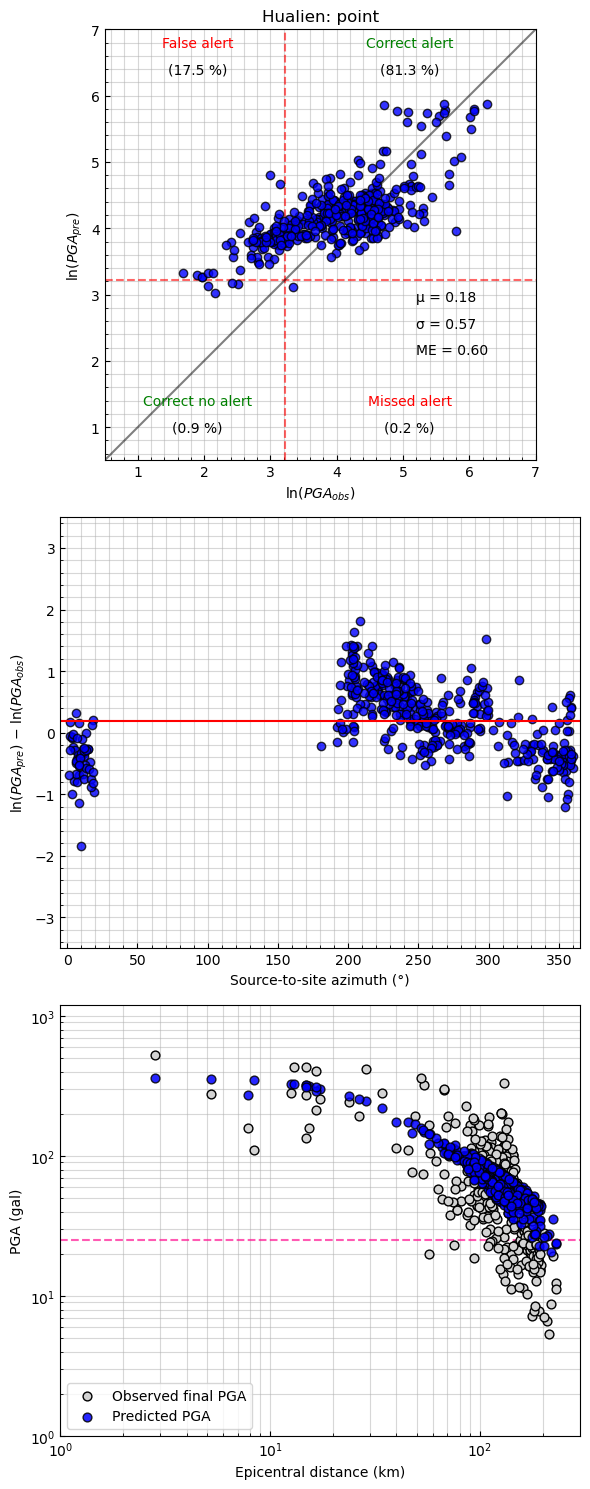

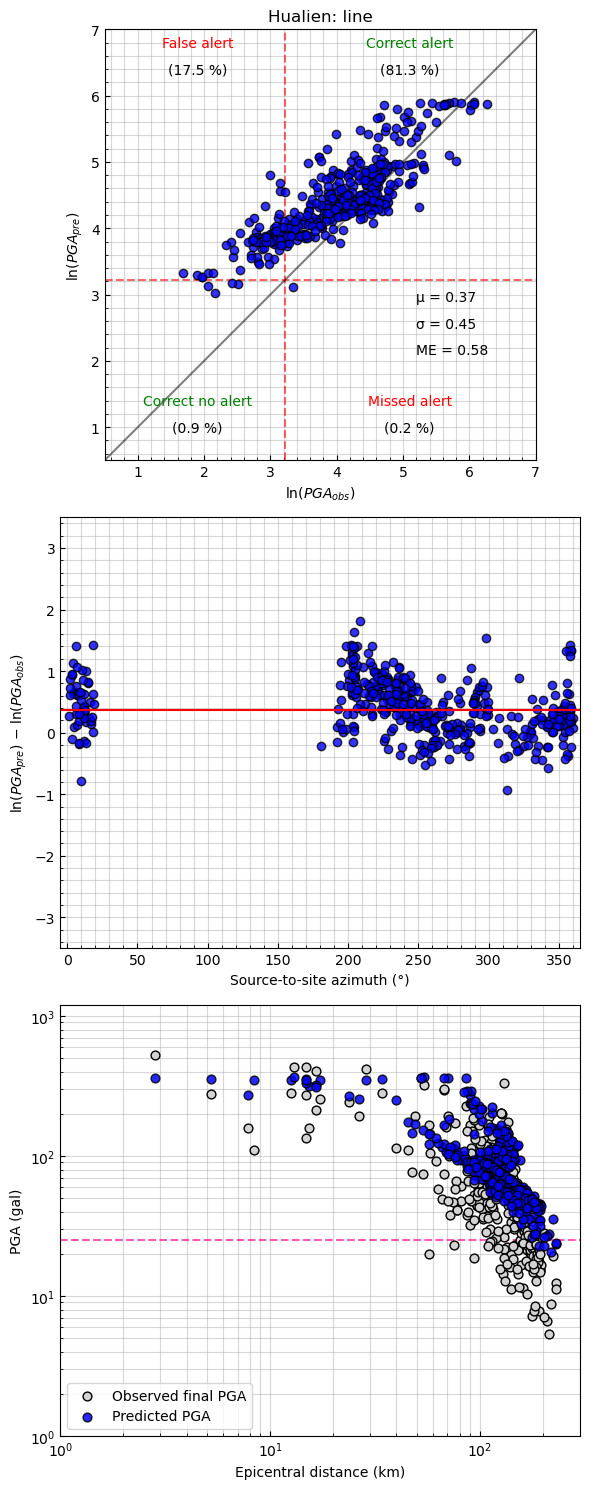

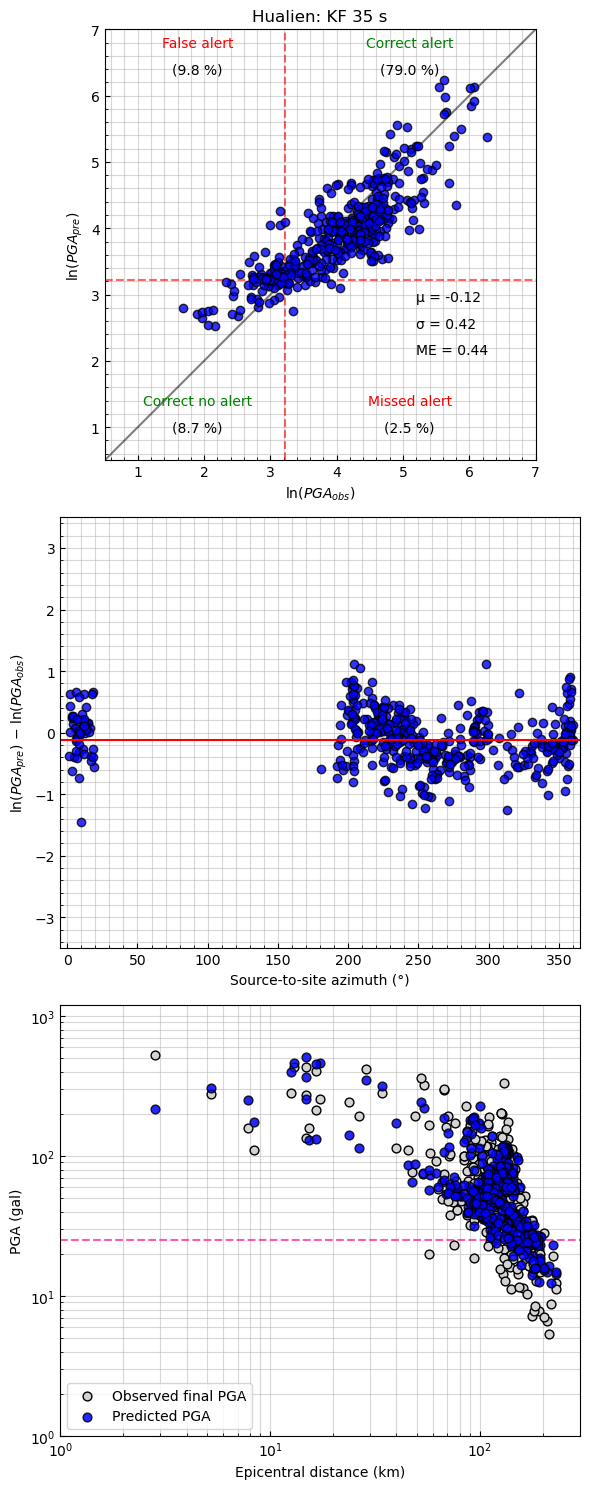

           mu  sigma    me  accuracy  missed_alert  false_alert
point    0.18   0.57  0.60     82.23          0.23        17.54
line     0.37   0.45  0.58     82.23          0.23        17.54
KF 35 s -0.12   0.42  0.44     87.70          2.51         9.79


In [6]:
def compare(pred, obs, threshold=25):
    residual = np.log(pred) - np.log(obs)
    mu, sigma = float(np.median(residual)), float(np.std(residual))
    n = pred.size
    return dict(
        mu=mu, sigma=sigma, me=float(np.sqrt(mu**2 + sigma**2)),
        accuracy=100 * np.sum((pred >= threshold) == (obs >= threshold)) / n,
        correct_alert=100 * np.sum((pred >= threshold) & (obs >= threshold)) / n,
        correct_no_alert=100 * np.sum((pred < threshold) & (obs < threshold)) / n,
        missed_alert=100 * np.sum((pred < threshold) & (obs >= threshold)) / n,
        false_alert=100 * np.sum((pred >= threshold) & (obs < threshold)) / n,
    )


def plot_comparison(pred, obs, azimuth, epi_dist, title):
    result = compare(pred, obs)
    pred_ln = np.log(pred)
    fig, ax = plt.subplots(3, 1, figsize=(6, 15))
    for a in ax:
        a.tick_params(axis="both", which="both", direction="in")
        a.minorticks_on()
        a.grid(which="both", alpha=0.5)
    ax[0].set_title(title)
    ax[0].axvline(np.log(25), color="r", lw=1.5, linestyle="--", alpha=0.6)
    ax[0].axhline(np.log(25), color="r", lw=1.5, linestyle="--", alpha=0.6)
    ax[0].plot([0, 1000], [0, 1000], "k-", lw=1.5, alpha=0.5)
    ax[0].plot(np.log(obs), pred_ln, "bo", markersize=6, mec="k", alpha=0.8)
    ax[0].set(xlim=[0.5, 7], ylim=[0.5, 7], xlabel=r"ln($PGA_{obs}$)", ylabel=r"ln($PGA_{pre}$)")
    ax[0].set_aspect("equal", adjustable="box")
    ax[0].text(5.2, 2.9, f"μ = {result['mu']:.2f}")
    ax[0].text(5.2, 2.5, f"σ = {result['sigma']:.2f}")
    ax[0].text(5.2, 2.1, f"ME = {result['me']:.2f}")
    quadrants = [("Correct alert", "correct_alert", "green", (5.1, 6.8)),
                 ("Correct no alert", "correct_no_alert", "green", (1.9, 1.4)),
                 ("False alert", "false_alert", "red", (1.9, 6.8)),
                 ("Missed alert", "missed_alert", "red", (5.1, 1.4))]
    for label, key, color, (x, y) in quadrants:
        ax[0].text(x, y, label, ha="center", va="center", color=color)
        ax[0].text(x, y - 0.4, f"({result[key]:.1f} %)", ha="center", va="center")
    residual = pred_ln - np.log(obs)
    ax[1].plot(azimuth, residual, "bo", markersize=6, mec="k", alpha=0.8)
    ax[1].axhline(result["mu"], color="red", lw=1.5)
    ax[1].set(xlim=[-5, 365], ylim=[-3.5, 3.5], xlabel="Source-to-site azimuth (°)",
              ylabel=r"ln($PGA_{pre}$) − ln($PGA_{obs}$)")
    ax[2].scatter(epi_dist, obs, s=40, facecolor="lightgray", edgecolor="k", label="Observed final PGA", zorder=3)
    ax[2].scatter(epi_dist, pred, s=40, facecolor="blue", edgecolor="k", alpha=0.85, label="Predicted PGA", zorder=4)
    ax[2].axhline(25, color="deeppink", lw=1.5, linestyle="--", alpha=0.7)
    ax[2].set(xscale="log", yscale="log", xlim=[1, 300], ylim=[1, 1200],
              xlabel="Epicentral distance (km)", ylabel="PGA (gal)")
    ax[2].legend(loc="lower left")
    fig.tight_layout()
    plt.show()
    return result


obs = final_pga[valid]
summary = {}
for method, pred in [("point", point_pga), ("line", line_pga), (f"KF {kf_second} s", kf_pga)]:
    summary[method] = plot_comparison(
        pred[valid], obs, stations["Azimuth"].to_numpy()[valid],
        stations["SRepi"].to_numpy()[valid], f"{bench['name']}: {method}",
    )
columns = ["mu", "sigma", "me", "accuracy", "missed_alert", "false_alert"]
print(pd.DataFrame(summary).T[columns].round(2).to_string())

## Optional: all events

Repeat the comparison for events 1–3 and print the summary table (no figures).

In [7]:
rows = []
for event_id, event_bench in BENCHMARKS.items():
    ev, ev_data, ev_depth = load_event(event_id)
    ev_stations = ev_data.loc[[INIT_SEC]].copy()
    ev_obs = ev_stations["EndRealPGA"].to_numpy()
    ev_valid = ev_obs > 0
    ev_kf, _ = kf_prediction(event_id, ev_data, ev_stations, ev_depth)
    for method, pred in [("point", point_source(event_bench, ev_stations, ev_depth)),
                         ("line", line_source(event_bench, ev, ev_stations, ev_depth)[0]),
                         ("KF", ev_kf)]:
        rows.append(dict(event=event_bench["name"], method=method,
                         **compare(pred[ev_valid], ev_obs[ev_valid])))
print(pd.DataFrame(rows)[["event", "method"] + columns].round(2).to_string(index=False))

    event method    mu  sigma   me  accuracy  missed_alert  false_alert
  Hualien  point  0.18   0.57 0.60     82.23          0.23        17.54
  Hualien   line  0.37   0.45 0.58     82.23          0.23        17.54
  Hualien     KF -0.12   0.42 0.44     87.70          2.51         9.79
  Meinong  point -0.15   0.70 0.72     85.08          7.26         7.66
  Meinong   line -0.10   0.66 0.67     86.09          6.25         7.66
  Meinong     KF -0.15   0.45 0.48     94.76          3.63         1.61
Chihshang  point  0.08   0.58 0.58     75.00         12.79        12.21
Chihshang   line  0.25   0.48 0.54     75.87          7.56        16.57
Chihshang     KF  0.12   0.53 0.54     78.78          9.01        12.21
